# API 5: Grid

One important feature of KANs is that they embed splines to neural networks. However, splines are only valid for approximating functions in known bounded regions, while the range of activations in neural networks may be changing over training. So we have to update grids properly according to that. Let's first take a look at how we parametrize splines. 

Text(0, 0.5, 'B_i(x)')

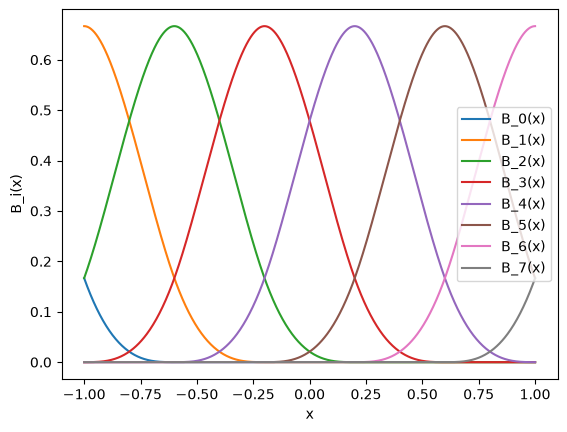

In [1]:
from xkan.spline import B_batch
import torch
import matplotlib.pyplot as plt
import numpy as np
from xkan.spline import extend_grid

# consider a 1D example.
# Suppose we have grid in [-1,1] with G intervals, spline order k
G = 5
k = 3
grid = torch.linspace(-1,1,steps=G+1)[None,:]
grid = extend_grid(grid, k_extend=k)

# and we have sample range in [-1,1]
x = torch.linspace(-1,1,steps=1001)[None,:]

basis = B_batch(x, grid, k=k)

for i in range(G+k):
    plt.plot(x[0].detach().numpy(), basis[0,:,i].detach().numpy())
    
plt.legend(['B_{}(x)'.format(i) for i in np.arange(G+k)])
plt.xlabel('x')
plt.ylabel('B_i(x)')

There are $G+k$ B-spline basis. The function is a linear combination of these bases $${\rm spline}(x)=\sum_{i=0}^{G+k-1} c_i B_i(x).$$ We don't need worry about the implementation since it's already built in KAN. But let's check if KAN is indeed implementing this. We initialize a [1,1] KAN, which is simply a 1D spline.

In [2]:
from xkan import KANNetwork

model = KANNetwork([1,1], grid=G, k=k)
# obtain coefficients c_i
model.layers[0].coef
assert(model.layers[0].coef[0].shape[1] == G+k)

# the model forward
model_output = model(x[0][:,None])

# spline output
spline_output = torch.einsum('j,ij->i',model.layers[0].coef[0][0], basis[0])[:,None]

torch.mean((model_output - spline_output)**2)

tensor(0.0040, grad_fn=<MeanBackward0>)

They are not the same, what's happening? We want to remind that we model the activation function to have two additive parts, a residual function $b$(x) plus the spline function, i.e., $$\phi(x)={\rm scale\_base}*b(x)+{\rm scale\_sp}*{\rm spline}(x),$$ and by default $b(x)={\rm silu}(x)=x/(1+e^{-x})$.

In [3]:
# residual output
residual_output = torch.nn.SiLU()(x[0][:,None])
scale_base = model.layers[0].scale_base
scale_sp = model.layers[0].scale_sp
torch.mean((model_output - (scale_base * residual_output + scale_sp * spline_output))**2)

tensor(0., grad_fn=<MeanBackward0>)

Your grid may not match your data: the grid spans [-1, 1], say, while the data lie in [-10, 10] or [-0.5, 0.5]. `update_grids` (in `xkan.nn`) moves the grids of every spline in every layer to the samples.

In [4]:
from xkan.nn import update_grids

model = KANNetwork([1,1], grid=G, k=k)
print(model.layers[0].grid) # by default, the grid is in [-1,1]
x = torch.linspace(-10,10,steps = 1001)[:,None]
update_grids(model, x)
print(model.layers[0].grid) # now the grid becomes in [-10,10]. We add a 0.01 margin in case x have zero variance

Parameter containing:
tensor([[-2.2000, -1.8000, -1.4000, -1.0000, -0.6000, -0.2000,  0.2000,  0.6000,
          1.0000,  1.4000,  1.8000,  2.2000]])
Parameter containing:
tensor([[-22.0000, -18.0000, -14.0000, -10.0000,  -6.0000,  -2.0000,   2.0000,
           6.0000,  10.0000,  14.0000,  18.0000,  22.0000]])


In [5]:
model = KANNetwork([1,1], grid=G, k=k)
print(model.layers[0].grid) # by default, the grid is in [-1,1]
x = torch.linspace(-0.5,0.5,steps = 1001)[:,None]
update_grids(model, x)
print(model.layers[0].grid) # now the grid becomes in [-10,10]. We add a 0.01 margin in case x have zero variance

Parameter containing:
tensor([[-2.2000, -1.8000, -1.4000, -1.0000, -0.6000, -0.2000,  0.2000,  0.6000,
          1.0000,  1.4000,  1.8000,  2.2000]])
Parameter containing:
tensor([[-1.1000, -0.9000, -0.7000, -0.5000, -0.3000, -0.1000,  0.1000,  0.3000,
          0.5000,  0.7000,  0.9000,  1.1000]])


You can choose a uniform grid or an adaptive one that puts about the same number of samples in each interval. `grid_eps` interpolates between the two: `grid_eps = 1` gives the uniform grid and `grid_eps = 0` the adaptive one. The default, `grid_eps = 0.02`, places the knots near the sample quantiles with a small uniform share.

In [6]:
# uniform grid
model = KANNetwork([1,1], grid=G, k=k, grid_eps=1.)
print(model.layers[0].grid) # by default, the grid is in [-1,1]
x = torch.normal(0,1,size=(1000,1))
update_grids(model, x)
print(model.layers[0].grid) # now the grid becomes in [-10,10]. We add a 0.01 margin in case x have zero variance

Parameter containing:
tensor([[-2.2000, -1.8000, -1.4000, -1.0000, -0.6000, -0.2000,  0.2000,  0.6000,
          1.0000,  1.4000,  1.8000,  2.2000]])
Parameter containing:
tensor([[-7.0724, -5.7702, -4.4680, -3.1658, -1.8636, -0.5614,  0.7408,  2.0430,
          3.3452,  4.6474,  5.9496,  7.2518]])


In [7]:
# adaptive grid based on sample distribution
model = KANNetwork([1,1], grid=G, k=k, grid_eps = 0.)
print(model.layers[0].grid) # by default, the grid is in [-1,1]
x = torch.normal(0,1,size=(1000,1))
update_grids(model, x)
print(model.layers[0].grid) # now the grid becomes in [-10,10]. We add a 0.01 margin in case x have zero variance

Parameter containing:
tensor([[-2.2000, -1.8000, -1.4000, -1.0000, -0.6000, -0.2000,  0.2000,  0.6000,
          1.0000,  1.4000,  1.8000,  2.2000]])
Parameter containing:
tensor([[-6.8559, -5.6479, -4.4399, -3.2318, -0.7814, -0.1846,  0.2934,  0.8231,
          2.8083,  4.0163,  5.2243,  6.4323]])
